In [28]:
!pip install pandas numpy matplotlib seaborn scikit-learn openpyxl

In [29]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Original dataset shape: (541909, 8)

First five rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate rows: 5268

Cleaned dataset shape: (392692, 9)
Remaining missing value

,CustomerID,Recency,Frequency,Monetary,Average_Purchase_Value,Purchase_Frequency,Historical_Value
0,12346,326,1,77183.60,77183.600000,1,77183.60
1,12347,2,7,4310.00,615.714286,7,4310.00
2,12348,75,4,1797.24,449.310000,4,1797.24
3,12349,19,1,1757.55,1757.550000,1,1757.55
4,12350,310,1,334.40,334.400000,1,334.40



Customer-level descriptive statistics:


,Average_Purchase_Value,Purchase_Frequency,Historical_Value
count,4338.00,4338.00,4338.00
mean,417.65,4.27,2048.69
std,1796.51,7.70,8985.23
min,3.45,1.00,3.75
25%,177.87,1.00,306.48
50%,291.94,2.00,668.57
75%,428.28,5.00,1660.60
max,84236.25,209.00,280206.02


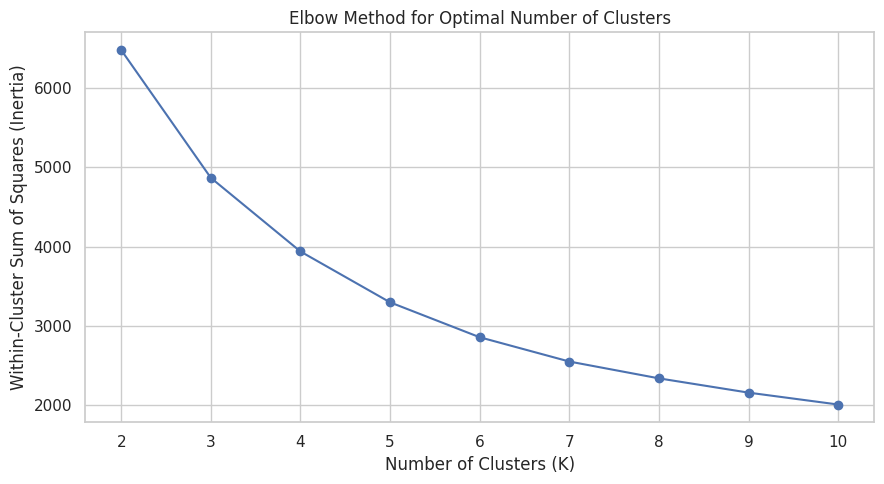

Selected number of clusters: 4
Silhouette score: 0.338

Cluster profiles:


,Customers,Average_Recency,Average_Frequency,Average_Monetary,Average_Purchase_Value,Total_Revenue
Cluster,,,,,,
0,713,12.17,13.75,8088.02,623.81,5766757.07
1,1622,181.51,1.32,341.00,282.45,553099.77
2,837,17.70,2.19,557.32,278.28,466479.03
3,1166,71.64,4.08,1801.78,579.69,2100873.02


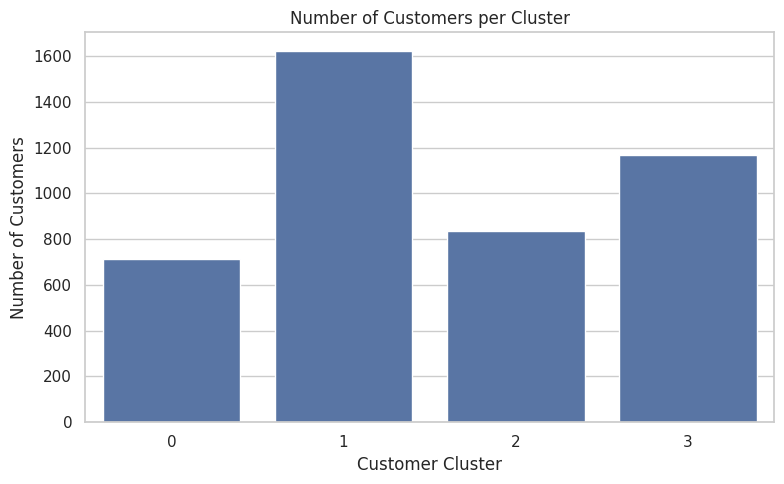

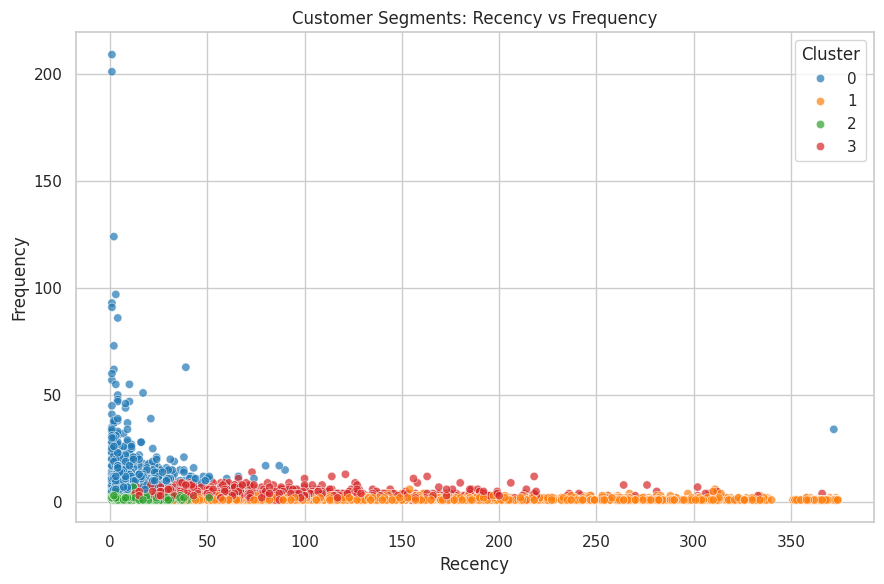

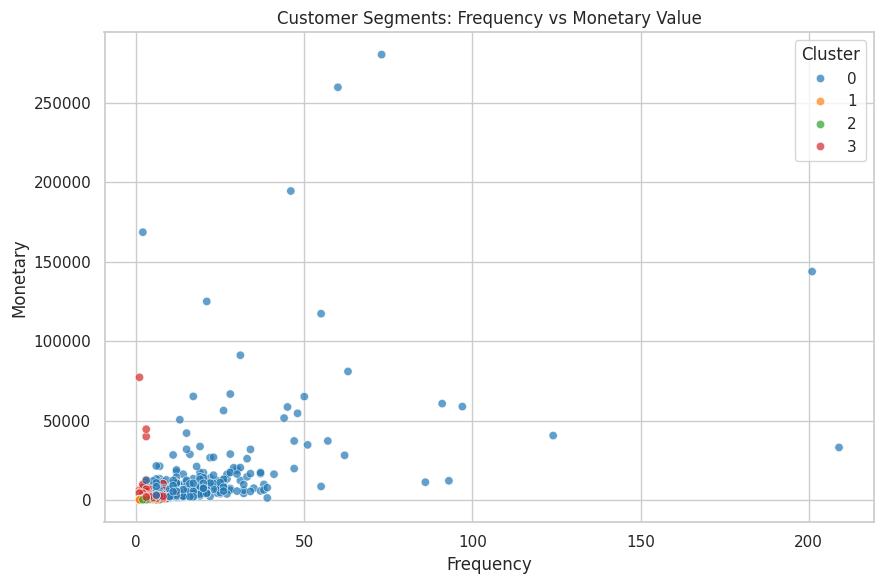

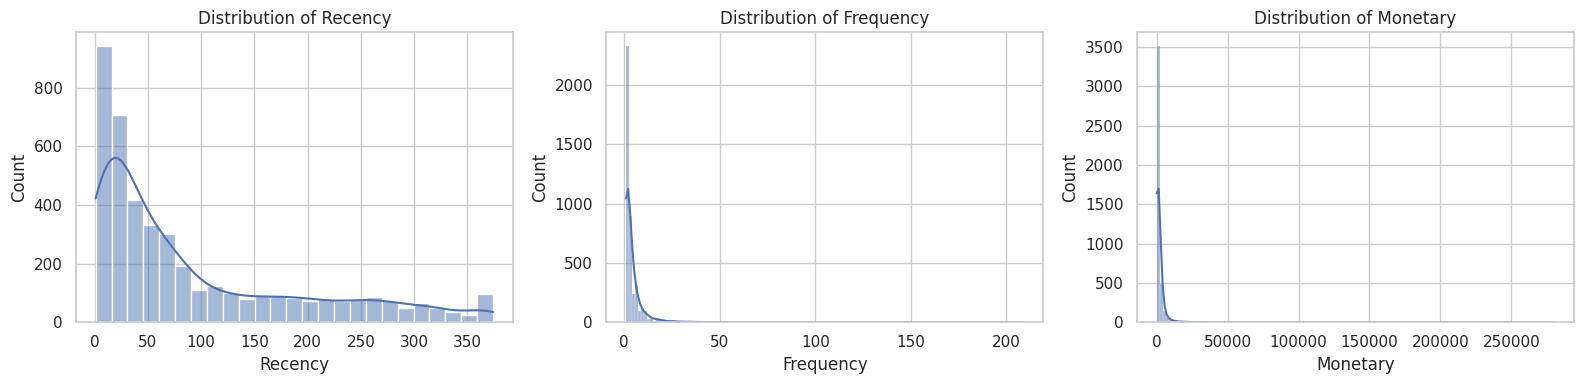

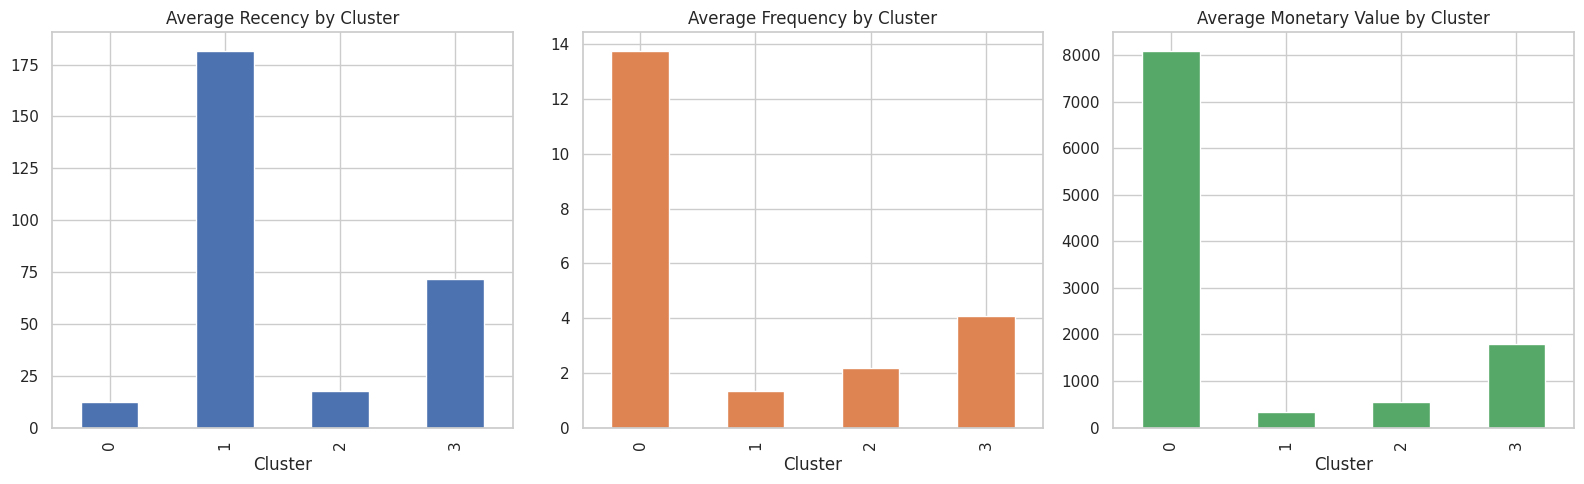


Final customer segment interpretation:


,Customers,Average_Recency,Average_Frequency,Average_Monetary,Average_Purchase_Value,Total_Revenue,Customer_Type,Marketing_Recommendation
Cluster,,,,,,,,
0,713,12.17,13.75,8088.02,623.81,5766757.07,High-value active customers,"Reward loyalty, provide VIP benefits and encou..."
1,1622,181.51,1.32,341.00,282.45,553099.77,Low-engagement customers,Test low-cost promotions and monitor engagemen...
2,837,17.70,2.19,557.32,278.28,466479.03,Low-engagement customers,Test low-cost promotions and monitor engagemen...
3,1166,71.64,4.08,1801.78,579.69,2100873.02,"Previously frequent, currently inactive customers",Run personalised win-back campaigns and target...



Analysis completed successfully.
Customer results saved as customer_segmentation_results.csv
Charts and cluster summary saved in the outputs folder.


In [30]:

# ============================================================
# OASIS INFOBYTE — TASK 2: CUSTOMER SEGMENTATION ANALYSIS
# ============================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# 1. CREATE OUTPUT FOLDER
os.makedirs("outputs", exist_ok=True)

# 2. LOAD DATASET
df = pd.read_excel("/content/Online Retail.xlsx")

print("Original dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nColumn information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# 3. CLEAN DATA
df.columns = df.columns.str.strip()

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")

df = df.drop_duplicates()

# Remove rows without essential customer or transaction information
df = df.dropna(subset=[
    "CustomerID", "InvoiceNo", "InvoiceDate", "Quantity", "UnitPrice"
])

# Remove cancelled invoices and non-purchase/invalid transaction lines
df["InvoiceNo"] = df["InvoiceNo"].astype(str)
df = df[~df["InvoiceNo"].str.startswith("C", na=False)]
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]

# Calculate transaction line revenue
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

# Make CustomerID consistent
df["CustomerID"] = df["CustomerID"].astype(str).str.replace(r"\.0$", "", regex=True)

print("\nCleaned dataset shape:", df.shape)
print("Remaining missing values:\n", df.isnull().sum())

# 4. CREATE CUSTOMER-LEVEL RFM DATA
# Use the day after the last transaction as the analysis date
analysis_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (analysis_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum")
).reset_index()

# 5. CALCULATE CUSTOMER VALUE METRICS
rfm["Average_Purchase_Value"] = rfm["Monetary"] / rfm["Frequency"]

# Historical purchase frequency: number of distinct invoices
rfm["Purchase_Frequency"] = rfm["Frequency"]

# Historical customer value proxy, not a forecast of future lifetime value
rfm["Historical_Value"] = rfm["Monetary"]

print("\nRFM sample:")
display(rfm.head())

print("\nCustomer-level descriptive statistics:")
display(rfm[
    ["Average_Purchase_Value", "Purchase_Frequency", "Historical_Value"]
].describe().round(2))

# 6. PREPARE FEATURES FOR CLUSTERING
features = ["Recency", "Frequency", "Monetary"]

# Reduce skew before standardising
X = rfm[features].copy()
X_log = np.log1p(X)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

# 7. ELBOW METHOD
inertia_values = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia_values.append(model.inertia_)

plt.figure(figsize=(9, 5))
plt.plot(list(k_values), inertia_values, marker="o")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Within-Cluster Sum of Squares (Inertia)")
plt.xticks(list(k_values))
plt.tight_layout()
plt.savefig("outputs/elbow_method.png", dpi=300)
plt.show()

# 8. SELECT K AFTER INSPECTING THE ELBOW PLOT
# Start with 4; change this if the elbow plot supports another value.
optimal_k = 4

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(X_scaled)

silhouette = silhouette_score(X_scaled, rfm["Cluster"])
print("Selected number of clusters:", optimal_k)
print("Silhouette score:", round(silhouette, 3))

# 9. CLUSTER PROFILES
cluster_profiles = rfm.groupby("Cluster").agg(
    Customers=("CustomerID", "count"),
    Average_Recency=("Recency", "mean"),
    Average_Frequency=("Frequency", "mean"),
    Average_Monetary=("Monetary", "mean"),
    Average_Purchase_Value=("Average_Purchase_Value", "mean"),
    Total_Revenue=("Monetary", "sum")
).round(2)

print("\nCluster profiles:")
display(cluster_profiles)

# 10. CLUSTER SIZE BAR CHART
plt.figure(figsize=(8, 5))
sns.countplot(data=rfm, x="Cluster")
plt.title("Number of Customers per Cluster")
plt.xlabel("Customer Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig("outputs/customers_per_cluster.png", dpi=300)
plt.show()

# 11. SCATTER PLOT: RECENCY VS FREQUENCY
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Frequency",
    hue="Cluster",
    palette="tab10",
    alpha=0.7
)
plt.title("Customer Segments: Recency vs Frequency")
plt.tight_layout()
plt.savefig("outputs/recency_vs_frequency.png", dpi=300)
plt.show()

# 12. SCATTER PLOT: FREQUENCY VS MONETARY
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="Cluster",
    palette="tab10",
    alpha=0.7
)
plt.title("Customer Segments: Frequency vs Monetary Value")
plt.tight_layout()
plt.savefig("outputs/frequency_vs_monetary.png", dpi=300)
plt.show()

# 13. RFM DISTRIBUTIONS
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, column in zip(axes, features):
    sns.histplot(data=rfm, x=column, kde=True, ax=ax)
    ax.set_title(f"Distribution of {column}")

plt.tight_layout()
plt.savefig("outputs/rfm_distributions.png", dpi=300)
plt.show()

# 14. CLUSTER PROFILE VISUALISATION
profile_for_plot = cluster_profiles[
    ["Average_Recency", "Average_Frequency", "Average_Monetary"]
]

profile_for_plot.plot(
    kind="bar",
    subplots=True,
    layout=(1, 3),
    figsize=(16, 5),
    legend=False,
    title=[
        "Average Recency by Cluster",
        "Average Frequency by Cluster",
        "Average Monetary Value by Cluster"
    ]
)

plt.tight_layout()
plt.savefig("outputs/cluster_profiles.png", dpi=300)
plt.show()

# 15. GENERATE SEGMENT DESCRIPTIONS AND MARKETING ACTIONS
# Interpret the actual cluster averages rather than assuming
# that a particular cluster number always represents the same segment.

overall_recency = rfm["Recency"].median()
overall_frequency = rfm["Frequency"].median()
overall_monetary = rfm["Monetary"].median()

def describe_cluster(row):
    recency = row["Average_Recency"]
    frequency = row["Average_Frequency"]
    monetary = row["Average_Monetary"]

    if recency <= overall_recency and frequency >= overall_frequency and monetary >= overall_monetary:
        return "High-value active customers"
    elif recency > overall_recency and frequency >= overall_frequency:
        return "Previously frequent, currently inactive customers"
    elif recency <= overall_recency and frequency < overall_frequency:
        return "Recent or promising customers"
    else:
        return "Low-engagement customers"

cluster_profiles["Customer_Type"] = cluster_profiles.apply(
    describe_cluster, axis=1
)

marketing_actions = {
    "High-value active customers":
        "Reward loyalty, provide VIP benefits and encourage referrals.",
    "Previously frequent, currently inactive customers":
        "Run personalised win-back campaigns and targeted return offers.",
    "Recent or promising customers":
        "Use welcome offers, product recommendations and repeat-purchase incentives.",
    "Low-engagement customers":
        "Test low-cost promotions and monitor engagement before increasing marketing spend."
}

cluster_profiles["Marketing_Recommendation"] = (
    cluster_profiles["Customer_Type"].map(marketing_actions)
)

print("\nFinal customer segment interpretation:")
display(cluster_profiles)

# 16. SAVE RESULTS
rfm.to_csv("customer_segmentation_results.csv", index=False)
cluster_profiles.to_csv("outputs/cluster_profiles_summary.csv")

print("\nAnalysis completed successfully.")
print("Customer results saved as customer_segmentation_results.csv")
print("Charts and cluster summary saved in the outputs folder.")
